# Predicción de la posición habitual de un jugador de fútbol
## 02 · Análisis exploratorio de datos (EDA) y KPIs

Proyecto final de Sistemas Inteligentes · UNAM · Matemáticas Aplicadas y Computación

## Objetivo

Conocer los datos antes de modelar: cómo se distribuye cada variable, cómo se relaciona con la **posición habitual** (lo que vamos a predecir), qué tan relacionadas están las habilidades entre sí y qué indicadores (KPIs) resumen el proyecto.

El análisis tiene estas partes: **univariado** (una variable a la vez), **bivariado** (cada variable contra la posición), **multivariado** (varias variables juntas, con correlaciones y PCA) y **KPIs**.

## Datos

Usamos `Datos_Limpios.csv`, que genera el cuaderno 01. Si en Colab no está, la celda de carga abre una ventana para subirlo. Opcionalmente usa `Bitacora_Limpieza.csv` para calcular cuántas respuestas se recibieron en total.

## Una nota sobre las matrices

Nuestra tabla de datos tiene **una fila por persona y una columna por variable** (por ejemplo, personas × 12 habilidades). Esa matriz **no es cuadrada**. En cambio, la **matriz de correlaciones** entre las 12 habilidades sí es **cuadrada** (12 × 12): compara cada habilidad con cada una de las demás. Esa es la matriz que analizamos en la parte multivariada, y es también la que **PCA** descompone para resumir las habilidades en pocos componentes.

## Aviso

Las habilidades son **autoevaluaciones** (cada persona se califica a sí misma de 1 a 5). Reflejan cómo se percibe cada jugador, no una medición objetiva. Además, la muestra es sobre todo de jugadores **recreativos**.

### Preparar el entorno
*Qué hace:* importa las herramientas, revisa si estamos en Google Colab y muestra las versiones.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import files  # solo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

try:
    from IPython.display import display
except ImportError:
    display = print

import sklearn
import scipy
print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| Colab:", EN_COLAB)

pandas 2.2.3 | numpy 2.4.6 | scipy 1.16.3 | scikit-learn 1.6.1 | Colab: True


### Cargar los datos
*Qué hace:* busca `Datos_Limpios.csv` (si no está, te pide subirlo) y lo lee.

In [2]:
ARCHIVO = "Datos_Limpios.csv"

if not os.path.exists(ARCHIVO):
    if EN_COLAB:
        print("Elige el archivo Datos_Limpios.csv (y, si quieres, Bitacora_Limpieza.csv) en la ventana que se abre...")
        files.upload()
    if not os.path.exists(ARCHIVO):
        raise FileNotFoundError(
            f"No se encontró '{ARCHIVO}'. Súbelo al panel de archivos de Colab con ese nombre exacto."
        )

datos = pd.read_csv(ARCHIVO, encoding="utf-8-sig")
print(f"Personas: {datos.shape[0]} | Columnas: {datos.shape[1]}")

HABILIDADES = [
    "velocidad", "resistencia", "fuerza", "control_balon", "regate", "pase",
    "definicion", "defensa", "juego_aereo", "vision_juego", "reflejos", "posicionamiento",
]
NOMBRES = {
    "velocidad": "Velocidad", "resistencia": "Resistencia", "fuerza": "Fuerza",
    "control_balon": "Control del balón", "regate": "Regate", "pase": "Pase",
    "definicion": "Definición", "defensa": "Defensa", "juego_aereo": "Juego aéreo",
    "vision_juego": "Visión de juego", "reflejos": "Reflejos", "posicionamiento": "Posicionamiento",
}
ORDEN_POSICION = [
    "Portero", "Defensa central", "Lateral", "Mediocampista defensivo",
    "Mediocampista ofensivo", "Extremo", "Delantero",
]
ORDEN_TIEMPO = ["Menos de 1 año", "De 1 a 2 años", "De 3 a 5 años", "De 6 a 10 años", "Más de 10 años"]
ORDEN_HORAS = ["Actualmente, ninguna", "De 1 a 2 horas", "De 3 a 5 horas", "De 6 a 8 horas", "De 9 a 12 horas", "Más de 12 horas"]
ORDEN_NIVEL = [
    "Escolar", "Recreativo (por diversión)", "Amateur en un equipo organizado",
    "Competitivo o semiprofesional", "Profesional",
]

assert set(datos["posicion"].unique()) == set(ORDEN_POSICION)
assert all(h in datos.columns for h in HABILIDADES)

Personas: 272 | Columnas: 27


## 1. Calidad de los datos y valores faltantes

*Qué hace:* cuenta los datos que faltan. Las únicas celdas vacías son las del "No sé / No puedo evaluarlo" en las habilidades. **No se rellenan**: en el EDA simplemente no se cuentan, y cada gráfica o cálculo indica con cuántas personas se hizo.

In [3]:
faltantes = datos.isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("faltantes")
faltantes["porcentaje"] = (faltantes["faltantes"] / len(datos) * 100).round(1)
print("Columnas con datos faltantes:")
display(faltantes)

personas_no_se = int((datos["n_no_se"] > 0).sum())
celdas_no_se = int(datos["n_no_se"].sum())
print(f"\nPersonas con al menos un 'No sé': {personas_no_se} | celdas en total: {celdas_no_se} de {len(datos) * len(HABILIDADES)}")

Columnas con datos faltantes:


,faltantes,porcentaje
velocidad,2,0.7
resistencia,1,0.4
fuerza,1,0.4
control_balon,2,0.7
regate,3,1.1
pase,1,0.4
definicion,1,0.4
defensa,1,0.4
juego_aereo,1,0.4
vision_juego,2,0.7



Personas con al menos un 'No sé': 5 | celdas en total: 17 de 3264


## 2. Análisis univariado

### Variable objetivo: posición habitual
*Qué hace:* cuenta cuántas personas hay en cada posición. Es la distribución de **lo que vamos a predecir**.

,personas,porcentaje
posicion,,
Portero,32,11.8
Defensa central,53,19.5
Lateral,41,15.1
Mediocampista defensivo,39,14.3
Mediocampista ofensivo,37,13.6
Extremo,27,9.9
Delantero,43,15.8


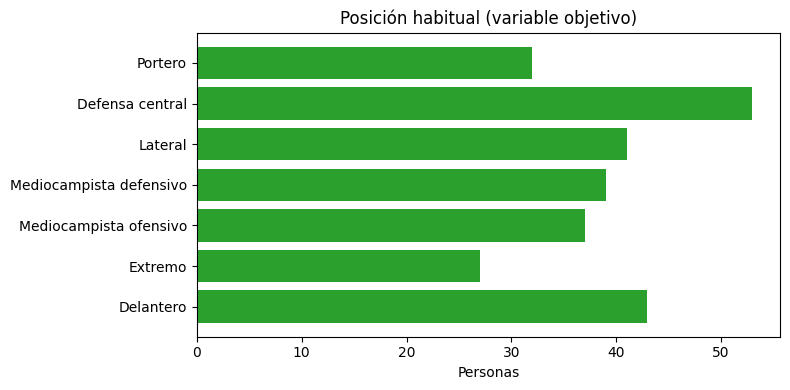

In [4]:
conteo = datos["posicion"].value_counts().reindex(ORDEN_POSICION)
tabla_posicion = conteo.to_frame("personas")
tabla_posicion["porcentaje"] = (conteo / conteo.sum() * 100).round(1)
display(tabla_posicion)

plt.figure(figsize=(8, 4))
plt.barh(conteo.index[::-1], conteo.values[::-1], color="tab:green")
plt.xlabel("Personas")
plt.title("Posición habitual (variable objetivo)")
plt.tight_layout()
plt.show()

### Edad, experiencia y nivel
*Qué hace:* resume la edad y muestra cómo se distribuyen el tiempo jugando, las horas por semana y el nivel.

,edad
count,272.0
mean,31.2
std,13.0
min,13.0
25%,20.0
50%,27.0
75%,42.0
max,90.0


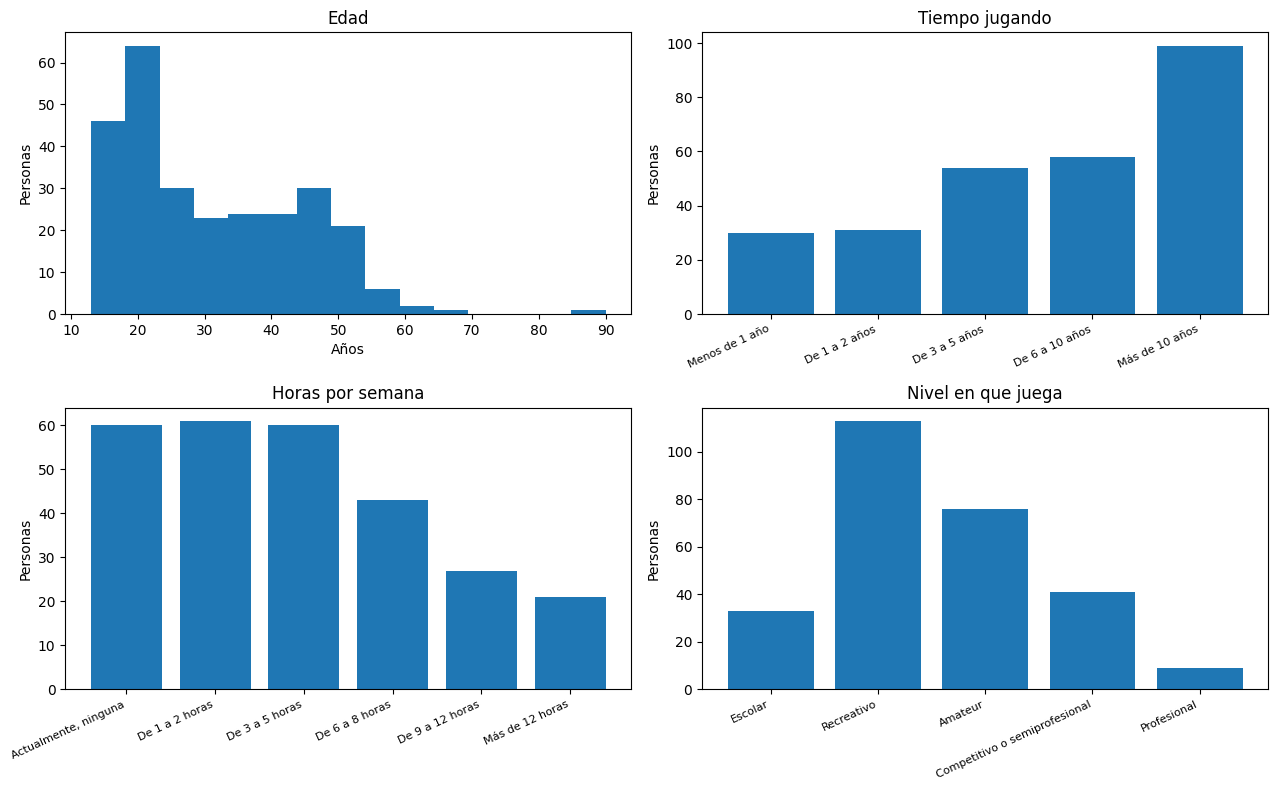

,% por nivel
nivel,
Escolar,12.1
Recreativo (por diversión),41.5
Amateur en un equipo organizado,27.9
Competitivo o semiprofesional,15.1
Profesional,3.3


In [5]:
display(datos["edad"].describe().round(1).to_frame("edad"))

fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
ejes[0, 0].hist(datos["edad"], bins=15, color="tab:blue")
ejes[0, 0].set_title("Edad")
ejes[0, 0].set_xlabel("Años")
ejes[0, 0].set_ylabel("Personas")

for eje, columna, orden, titulo in [
    (ejes[0, 1], "tiempo_juego", ORDEN_TIEMPO, "Tiempo jugando"),
    (ejes[1, 0], "horas_semana", ORDEN_HORAS, "Horas por semana"),
    (ejes[1, 1], "nivel", ORDEN_NIVEL, "Nivel en que juega"),
]:
    valores = datos[columna].value_counts().reindex(orden)
    eje.bar(range(len(orden)), valores.values, color="tab:blue")
    eje.set_xticks(range(len(orden)))
    eje.set_xticklabels([o.replace(" (por diversión)", "").replace(" en un equipo organizado", "") for o in orden],
                        rotation=25, ha="right", fontsize=8)
    eje.set_title(titulo)
    eje.set_ylabel("Personas")
plt.tight_layout()
plt.show()

nivel = datos["nivel"].value_counts().reindex(ORDEN_NIVEL)
display((nivel / nivel.sum() * 100).round(1).to_frame("% por nivel"))

### Habilidades
*Qué hace:* para cada habilidad muestra el porcentaje de personas que se puso 1, 2, 3, 4 o 5, y su promedio y desviación. Sirve para ver si hay **habilidades casi sin variación** (que aportarían poco a un modelo).

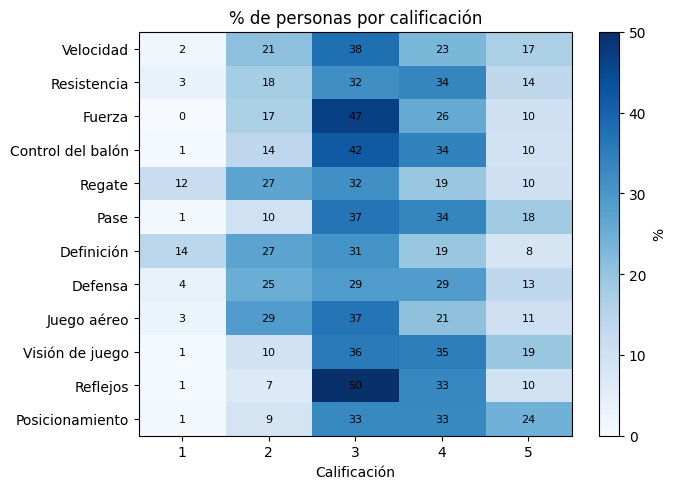

,count,mean,std,min,max
Velocidad,270.0,3.32,1.04,1.0,5.0
Resistencia,271.0,3.37,1.03,1.0,5.0
Fuerza,271.0,3.29,0.88,1.0,5.0
Control del balón,270.0,3.38,0.87,1.0,5.0
Regate,269.0,2.90,1.16,1.0,5.0
Pase,271.0,3.58,0.94,1.0,5.0
Definición,271.0,2.81,1.15,1.0,5.0
Defensa,271.0,3.23,1.08,1.0,5.0
Juego aéreo,271.0,3.07,1.02,1.0,5.0
Visión de juego,270.0,3.62,0.93,1.0,5.0


In [6]:
distribucion = pd.DataFrame(
    {h: datos[h].value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0) * 100 for h in HABILIDADES}
).T
distribucion.columns = ["1", "2", "3", "4", "5"]
distribucion.index = [NOMBRES[h] for h in distribucion.index]

fig, eje = plt.subplots(figsize=(7, 5))
imagen = eje.imshow(distribucion.values, cmap="Blues", vmin=0, vmax=50, aspect="auto")
eje.set_xticks(range(5))
eje.set_xticklabels(distribucion.columns)
eje.set_yticks(range(len(distribucion)))
eje.set_yticklabels(distribucion.index)
for i in range(distribucion.shape[0]):
    for j in range(distribucion.shape[1]):
        eje.text(j, i, f"{distribucion.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
eje.set_xlabel("Calificación")
eje.set_title("% de personas por calificación")
plt.colorbar(imagen, label="%")
plt.tight_layout()
plt.show()

estadisticas = datos[HABILIDADES].agg(["count", "mean", "std", "min", "max"]).T.round(2)
estadisticas.index = [NOMBRES[h] for h in estadisticas.index]
display(estadisticas)

## 3. Análisis bivariado (cada variable contra la posición)

### Perfil promedio de cada posición
*Qué hace:* calcula el promedio de cada habilidad para cada posición. El primer mapa muestra los promedios (1 a 5). El segundo muestra **cuánto se aleja** cada posición del promedio de todos (en desviaciones estándar): es lo que realmente distingue a una posición de las demás.

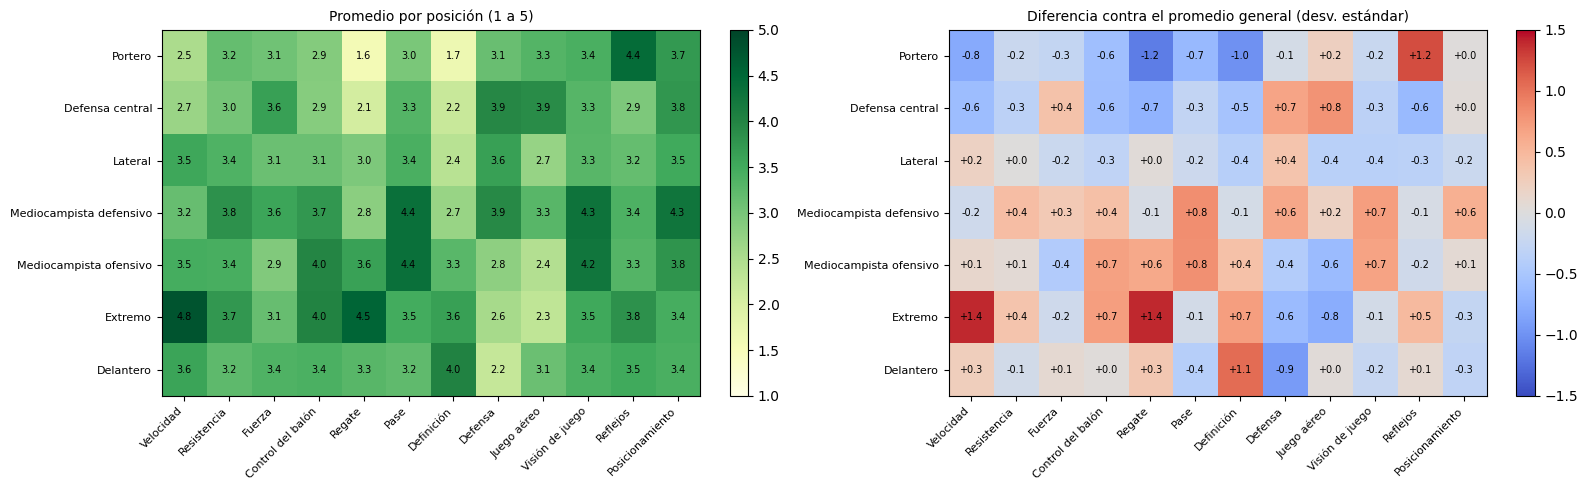

In [7]:
perfil = datos.groupby("posicion")[HABILIDADES].mean().reindex(ORDEN_POSICION)
global_media = datos[HABILIDADES].mean()
global_desv = datos[HABILIDADES].std()
perfil_z = (perfil - global_media) / global_desv

etiquetas_hab = [NOMBRES[h] for h in HABILIDADES]
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
for eje, matriz, titulo, cmap, vmin, vmax, formato in [
    (ejes[0], perfil, "Promedio por posición (1 a 5)", "YlGn", 1, 5, "{:.1f}"),
    (ejes[1], perfil_z, "Diferencia contra el promedio general (desv. estándar)", "coolwarm", -1.5, 1.5, "{:+.1f}"),
]:
    imagen = eje.imshow(matriz.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    eje.set_xticks(range(len(HABILIDADES)))
    eje.set_xticklabels(etiquetas_hab, rotation=45, ha="right", fontsize=8)
    eje.set_yticks(range(len(ORDEN_POSICION)))
    eje.set_yticklabels(ORDEN_POSICION, fontsize=8)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            eje.text(j, i, formato.format(matriz.values[i, j]), ha="center", va="center", fontsize=7)
    eje.set_title(titulo, fontsize=10)
    plt.colorbar(imagen, ax=eje, fraction=0.04)
plt.tight_layout()
plt.show()

### ¿Qué habilidades separan mejor las posiciones?
*Qué hace:* para cada habilidad aplica la prueba de **Kruskal-Wallis** (compara las 7 posiciones sin suponer que los datos sean "normales"). El **tamaño del efecto** (ε², de 0 a 1) dice *cuánto* separa la habilidad a las posiciones, y es más útil que el valor p. Como son 12 pruebas, el umbral de significancia se ajusta (0.05 / 12).

Ojo: separar las posiciones no significa "predecir mejor"; y al ser autoevaluaciones, parte del efecto puede venir de que cada persona **se describe según su posición**.

,habilidad,personas,H,valor_p,efecto_e2,significativa
0,Regate,269,137.7,3.01e-27,0.514,sí
1,Definición,271,120.9,1.04e-23,0.448,sí
2,Defensa,271,100.1,2.43e-19,0.371,sí
3,Velocidad,270,96.4,1.45e-18,0.358,sí
4,Reflejos,271,78.5,7.33e-15,0.291,sí
5,Pase,271,78.4,7.65e-15,0.290,sí
6,Control del balón,270,76.2,2.22e-14,0.283,sí
7,Juego aéreo,271,74.8,4.20e-14,0.277,sí
8,Visión de juego,270,50.9,3.13e-09,0.189,sí
9,Fuerza,271,24.6,4.06e-04,0.091,sí


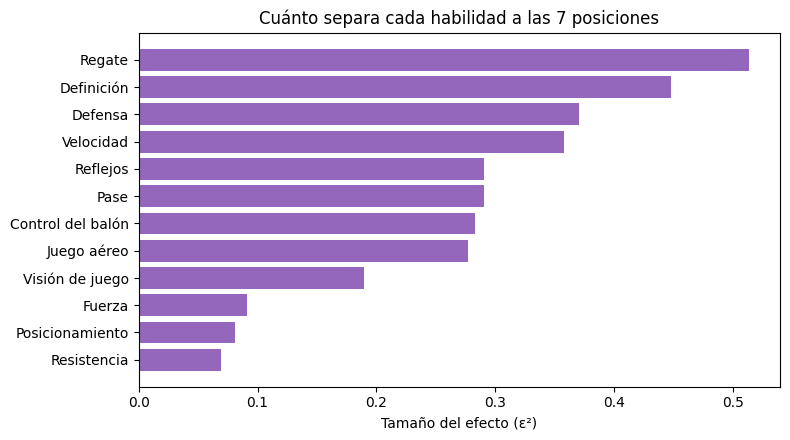

In [8]:
filas = []
for h in HABILIDADES:
    sub = datos[["posicion", h]].dropna()
    grupos = [sub.loc[sub["posicion"] == p, h].to_numpy(dtype=float) for p in ORDEN_POSICION]
    H, p = stats.kruskal(*grupos)
    n = len(sub)
    filas.append({"habilidad": NOMBRES[h], "personas": n, "H": H, "valor_p": p, "efecto_e2": H / (n - 1)})

separacion = pd.DataFrame(filas).sort_values("efecto_e2", ascending=False).reset_index(drop=True)
UMBRAL = 0.05 / len(HABILIDADES)
separacion["significativa"] = np.where(separacion["valor_p"] < UMBRAL, "sí", "no")
tabla_sep = separacion.copy()
tabla_sep["H"] = tabla_sep["H"].round(1)
tabla_sep["efecto_e2"] = tabla_sep["efecto_e2"].round(3)
tabla_sep["valor_p"] = tabla_sep["valor_p"].map(lambda v: f"{v:.2e}")
display(tabla_sep)

plt.figure(figsize=(8, 4.5))
plt.barh(separacion["habilidad"][::-1], separacion["efecto_e2"][::-1], color="tab:purple")
plt.xlabel("Tamaño del efecto (ε²)")
plt.title("Cuánto separa cada habilidad a las 7 posiciones")
plt.tight_layout()
plt.show()

### Nivel y posición
*Qué hace:* cruza el nivel en que juega cada persona con su posición, en porcentaje de cada posición. Sirve para ver si ciertas posiciones se concentran en ciertos niveles. Se calcula también la prueba chi-cuadrada y cuántas celdas tienen muy pocas personas (por debajo de 5 esperadas), porque entonces la prueba es poco fiable.

In [9]:
cruce = pd.crosstab(datos["posicion"], datos["nivel"]).reindex(index=ORDEN_POSICION, columns=ORDEN_NIVEL)
display(cruce)
display((cruce.div(cruce.sum(axis=1), axis=0) * 100).round(0))

chi2, p_chi, grados, esperadas = stats.chi2_contingency(cruce.to_numpy())
celdas_pocas = int((esperadas < 5).sum())
print(f"Chi-cuadrada: p = {p_chi:.3f} | celdas con menos de 5 esperadas: {celdas_pocas} de {esperadas.size}")

nivel,Escolar,Recreativo (por diversión),Amateur en un equipo organizado,Competitivo o semiprofesional,Profesional
posicion,,,,,
Portero,2,16,7,6,1
Defensa central,7,24,12,8,2
Lateral,7,20,11,3,0
Mediocampista defensivo,3,11,16,7,2
Mediocampista ofensivo,4,15,12,3,3
Extremo,8,4,10,5,0
Delantero,2,23,8,9,1


nivel,Escolar,Recreativo (por diversión),Amateur en un equipo organizado,Competitivo o semiprofesional,Profesional
posicion,,,,,
Portero,6.0,50.0,22.0,19.0,3.0
Defensa central,13.0,45.0,23.0,15.0,4.0
Lateral,17.0,49.0,27.0,7.0,0.0
Mediocampista defensivo,8.0,28.0,41.0,18.0,5.0
Mediocampista ofensivo,11.0,41.0,32.0,8.0,8.0
Extremo,30.0,15.0,37.0,19.0,0.0
Delantero,5.0,53.0,19.0,21.0,2.0


Chi-cuadrada: p = 0.055 | celdas con menos de 5 esperadas: 14 de 35


### Edad, experiencia y horas contra la posición
*Qué hace:* compara la edad de cada posición con cajas (boxplots) y la mediana de las variables de experiencia.

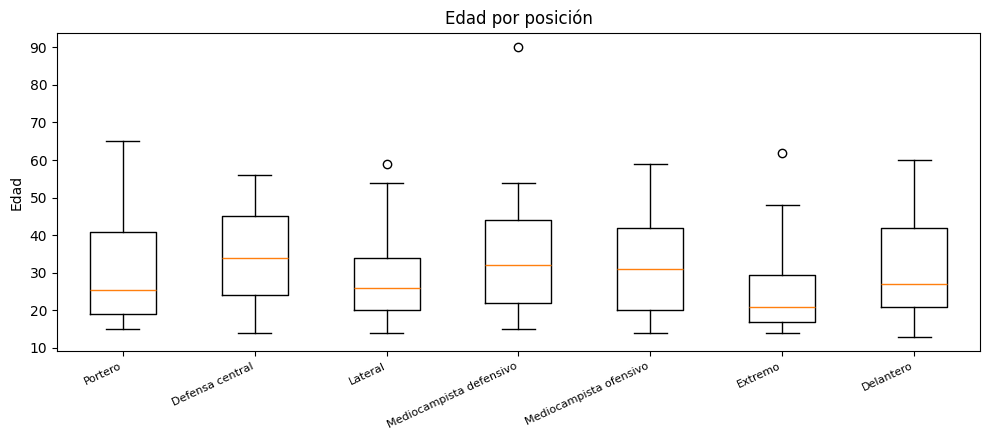

,edad (mediana),"tiempo jugando (código 0-4, mediana)","horas por semana (código 0-5, mediana)"
posicion,,,
Portero,25.5,3.0,2.0
Defensa central,34.0,3.0,1.0
Lateral,26.0,2.0,2.0
Mediocampista defensivo,32.0,4.0,2.0
Mediocampista ofensivo,31.0,3.0,2.0
Extremo,21.0,2.0,2.0
Delantero,27.0,3.0,1.0


In [10]:
grupos_edad = [datos.loc[datos["posicion"] == p, "edad"] for p in ORDEN_POSICION]
fig, eje = plt.subplots(figsize=(10, 4.5))
eje.boxplot(grupos_edad)
eje.set_xticks(range(1, len(ORDEN_POSICION) + 1))
eje.set_xticklabels(ORDEN_POSICION, rotation=25, ha="right", fontsize=8)
eje.set_ylabel("Edad")
eje.set_title("Edad por posición")
plt.tight_layout()
plt.show()

experiencia = datos.groupby("posicion")[["edad", "tiempo_codigo", "horas_codigo"]].median().reindex(ORDEN_POSICION)
experiencia.columns = ["edad (mediana)", "tiempo jugando (código 0-4, mediana)", "horas por semana (código 0-5, mediana)"]
display(experiencia)

## 4. Análisis multivariado (varias variables a la vez)

### Matriz de correlaciones (cuadrada, 12 × 12)
*Qué hace:* mide qué tan relacionadas están las habilidades entre sí con la correlación de **Spearman** (apropiada para escalas de 1 a 5). Cada celda compara dos habilidades. Un valor cercano a 1 significa que quien se califica alto en una tiende a calificarse alto en la otra. Como el cálculo usa todas las personas con ambos datos, la matriz no necesita rellenar los "No sé".

Forma de la matriz de datos (personas x habilidades): (272, 12) -> no es cuadrada
Forma de la matriz de correlaciones: (12, 12) -> cuadrada


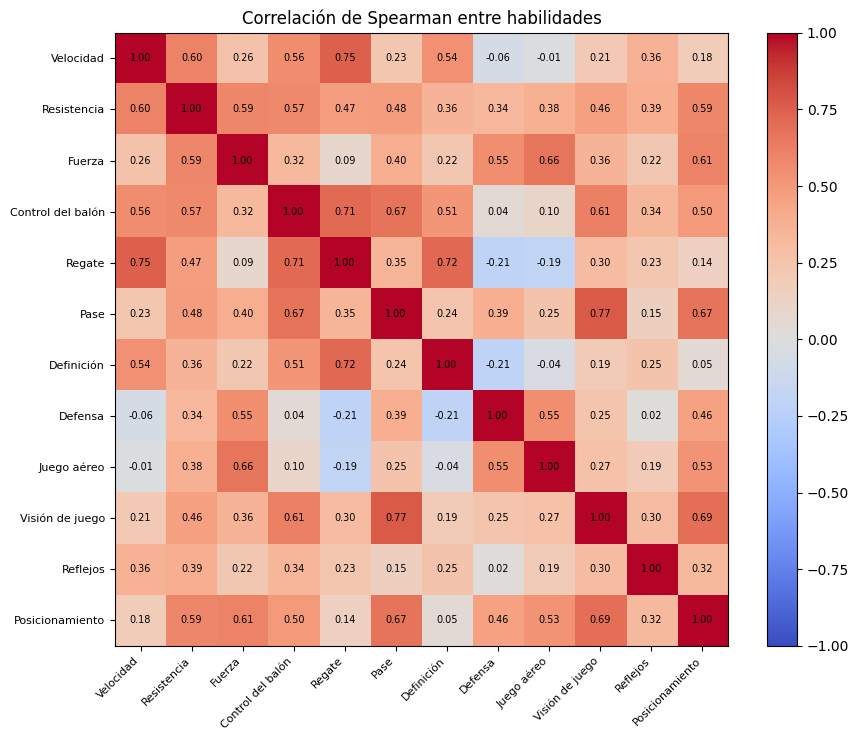

Parejas más relacionadas:


,habilidad_a,habilidad_b,correlacion
0,Pase,Visión de juego,0.77
1,Velocidad,Regate,0.75
2,Regate,Definición,0.72
3,Control del balón,Regate,0.71
4,Visión de juego,Posicionamiento,0.69
5,Pase,Posicionamiento,0.67


Parejas menos relacionadas o con relación negativa:


,habilidad_a,habilidad_b,correlacion
62,Control del balón,Defensa,0.04
63,Definición,Juego aéreo,-0.04
64,Defensa,Reflejos,0.02
65,Velocidad,Juego aéreo,-0.01


In [11]:
correlacion = datos[HABILIDADES].corr(method="spearman")
print("Forma de la matriz de datos (personas x habilidades):", datos[HABILIDADES].shape, "-> no es cuadrada")
print("Forma de la matriz de correlaciones:", correlacion.shape, "-> cuadrada")

fig, eje = plt.subplots(figsize=(9, 7.5))
imagen = eje.imshow(correlacion.values, vmin=-1, vmax=1, cmap="coolwarm")
eje.set_xticks(range(len(HABILIDADES)))
eje.set_yticks(range(len(HABILIDADES)))
eje.set_xticklabels(etiquetas_hab, rotation=45, ha="right", fontsize=8)
eje.set_yticklabels(etiquetas_hab, fontsize=8)
for i in range(len(HABILIDADES)):
    for j in range(len(HABILIDADES)):
        eje.text(j, i, f"{correlacion.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(imagen, fraction=0.04)
plt.title("Correlación de Spearman entre habilidades")
plt.tight_layout()
plt.show()

pares = []
for i in range(len(HABILIDADES)):
    for j in range(i + 1, len(HABILIDADES)):
        pares.append((NOMBRES[HABILIDADES[i]], NOMBRES[HABILIDADES[j]], correlacion.values[i, j]))
pares = pd.DataFrame(pares, columns=["habilidad_a", "habilidad_b", "correlacion"])
pares["abs"] = pares["correlacion"].abs()
pares = pares.sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True)
print("Parejas más relacionadas:")
display(pares.head(6).round(2))
print("Parejas menos relacionadas o con relación negativa:")
display(pares.tail(4).round(2))

### PCA: ¿se pueden resumir las 12 habilidades?
*Qué hace:* **PCA** (Análisis de Componentes Principales) combina las 12 habilidades en componentes nuevos, ordenados por cuánta variación de los datos explican. Si las habilidades están muy relacionadas, unos pocos componentes bastan para resumirlas. Aquí se usa **solo para explorar**: se aplica a las personas con las 12 habilidades contestadas (las que dijeron "No sé" quedan fuera de este cálculo, sin rellenar nada).

Ventaja de PCA: reduce dimensiones y quita redundancia. Desventaja: los componentes son combinaciones de variables, y es **más difícil explicar** un resultado con ellos que con las habilidades originales. Por eso, en el modelado se comparará **con y sin PCA**.

Personas usadas en el PCA: 267 de 272
Varianza explicada: PC1 = 42.5% | PC1+PC2 = 63.9% | PC1+PC2+PC3 = 73.8%
Componentes necesarios para explicar el 80 %: 4 | el 90 %: 7 (de 12)


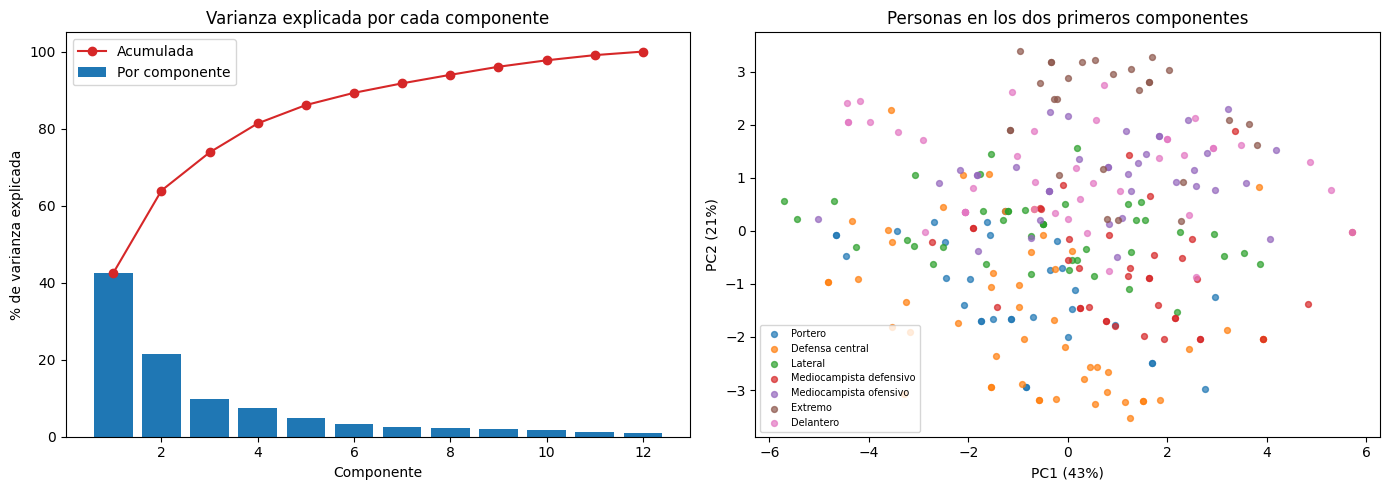

Peso de cada habilidad en los tres primeros componentes:


,PC1,PC2,PC3
Velocidad,0.27,0.34,-0.32
Resistencia,0.36,0.01,-0.24
Fuerza,0.30,-0.26,-0.34
Control del balón,0.36,0.20,0.23
Regate,0.26,0.45,-0.01
Pase,0.34,-0.08,0.48
Definición,0.23,0.37,-0.19
Defensa,0.17,-0.44,-0.11
Juego aéreo,0.21,-0.40,-0.31
Visión de juego,0.33,-0.07,0.47


In [12]:
completos = datos.dropna(subset=HABILIDADES).copy()
escala = StandardScaler().fit_transform(completos[HABILIDADES].to_numpy(dtype=float))
pca = PCA(svd_solver="full")
componentes = pca.fit_transform(escala)

varianza = pca.explained_variance_ratio_
acumulada = np.cumsum(varianza)
n_80 = int(np.searchsorted(acumulada, 0.80) + 1)
n_90 = int(np.searchsorted(acumulada, 0.90) + 1)
print(f"Personas usadas en el PCA: {len(completos)} de {len(datos)}")
print(f"Varianza explicada: PC1 = {varianza[0]:.1%} | PC1+PC2 = {acumulada[1]:.1%} | PC1+PC2+PC3 = {acumulada[2]:.1%}")
print(f"Componentes necesarios para explicar el 80 %: {n_80} | el 90 %: {n_90} (de {len(HABILIDADES)})")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
ejes[0].bar(range(1, len(varianza) + 1), varianza * 100, color="tab:blue", label="Por componente")
ejes[0].plot(range(1, len(varianza) + 1), acumulada * 100, color="tab:red", marker="o", label="Acumulada")
ejes[0].set_xlabel("Componente")
ejes[0].set_ylabel("% de varianza explicada")
ejes[0].set_title("Varianza explicada por cada componente")
ejes[0].legend()

mapa_colores = plt.get_cmap("tab10")
for i, posicion in enumerate(ORDEN_POSICION):
    marca = (completos["posicion"] == posicion).to_numpy()
    ejes[1].scatter(componentes[marca, 0], componentes[marca, 1], s=18, alpha=0.7,
                    color=mapa_colores(i), label=posicion)
ejes[1].set_xlabel(f"PC1 ({varianza[0]:.0%})")
ejes[1].set_ylabel(f"PC2 ({varianza[1]:.0%})")
ejes[1].set_title("Personas en los dos primeros componentes")
ejes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

pesos = pd.DataFrame(pca.components_[:3].T, index=etiquetas_hab, columns=["PC1", "PC2", "PC3"]).round(2)
print("Peso de cada habilidad en los tres primeros componentes:")
display(pesos)

## 5. KPIs (indicadores clave)

*Qué hace:* reúne en una tabla los indicadores que resumen los datos del proyecto. Son **KPIs de los datos y de la muestra**; los KPIs del modelo (por ejemplo, el desempeño frente al modelo base) se añaden después del modelado. Esta tabla alimenta el tablero.

In [13]:
excluidas = None
if os.path.exists("Bitacora_Limpieza.csv"):
    bit = pd.read_csv("Bitacora_Limpieza.csv", encoding="utf-8-sig")
    fila = bit.loc[bit["paso"] == "Exclusión por regla", "filas_afectadas"]
    if len(fila) == 1:
        excluidas = int(fila.iloc[0])

validos = len(datos)
recibidas = validos + excluidas if excluidas is not None else None
recreativo = float((datos["nivel"] == "Recreativo (por diversión)").mean() * 100)
organizado = float(datos["nivel"].isin(
    ["Amateur en un equipo organizado", "Competitivo o semiprofesional", "Profesional"]).mean() * 100)
mejor_habilidad = separacion.iloc[0]
razon = conteo.max() / conteo.min()

kpis = [
    ("Participantes válidos", validos, "Personas con posición habitual y habilidades contestadas"),
    ("Respuestas recibidas", recibidas if recibidas is not None else "sin bitácora", "Incluye quienes respondieron 'No' a la pregunta 1"),
    ("% de respuestas válidas", round(100 * validos / recibidas, 1) if recibidas else "sin bitácora", "Válidas / recibidas"),
    ("Edad mediana", float(datos["edad"].median()), "Años"),
    ("% menores de 18 años", round(float(datos["menor_18"].mean() * 100), 1), "Sobre los participantes válidos"),
    ("% que juega por diversión", round(recreativo, 1), "Nivel 'Recreativo (por diversión)'"),
    ("% en equipo organizado o más", round(organizado, 1), "Amateur, competitivo o profesional"),
    ("Posición más frecuente", f"{conteo.idxmax()} ({int(conteo.max())})", "Personas"),
    ("Posición menos frecuente", f"{conteo.idxmin()} ({int(conteo.min())})", "Personas"),
    ("Razón de desbalance", round(float(razon), 2), "Más frecuente / menos frecuente"),
    ("Habilidad que más separa posiciones", f"{mejor_habilidad['habilidad']} (ε² = {mejor_habilidad['efecto_e2']:.2f})", "Prueba de Kruskal-Wallis"),
    ("% de celdas 'No sé'", round(100 * celdas_no_se / (validos * len(HABILIDADES)), 2), "Sobre todas las habilidades"),
    ("Varianza explicada por PC1 + PC2", f"{acumulada[1]:.1%}", "PCA exploratorio"),
    ("Componentes para explicar 80 %", n_80, f"De {len(HABILIDADES)} habilidades"),
    ("Azar entre las 7 posiciones", round(100 / len(ORDEN_POSICION), 1), "% de acierto de adivinar al azar"),
    ("Modelo base (siempre la más común)", round(float(100 * conteo.max() / validos), 1), "% de acierto de decir siempre la posición más frecuente"),
]
tabla_kpis = pd.DataFrame(kpis, columns=["kpi", "valor", "descripcion"])
tabla_kpis["valor"] = tabla_kpis["valor"].astype(str)
display(tabla_kpis)

,kpi,valor,descripcion
0,Participantes válidos,272,Personas con posición habitual y habilidades c...
1,Respuestas recibidas,290,Incluye quienes respondieron 'No' a la pregunta 1
2,% de respuestas válidas,93.8,Válidas / recibidas
3,Edad mediana,27.0,Años
4,% menores de 18 años,12.1,Sobre los participantes válidos
5,% que juega por diversión,41.5,Nivel 'Recreativo (por diversión)'
6,% en equipo organizado o más,46.3,"Amateur, competitivo o profesional"
7,Posición más frecuente,Defensa central (53),Personas
8,Posición menos frecuente,Extremo (27),Personas
9,Razón de desbalance,1.96,Más frecuente / menos frecuente


## 6. Guardar las tablas para el tablero
*Qué hace:* guarda los KPIs, el perfil promedio por posición y la matriz de correlaciones, para usarlos en el tablero.

In [14]:
tabla_kpis.to_csv("KPIs_EDA.csv", index=False, encoding="utf-8-sig")

perfil_guardar = perfil.copy()
perfil_guardar.columns = etiquetas_hab
perfil_guardar.round(3).rename_axis("posicion").reset_index().to_csv(
    "Perfil_Habilidades_por_Posicion.csv", index=False, encoding="utf-8-sig")

correlacion_guardar = correlacion.copy()
correlacion_guardar.index = etiquetas_hab
correlacion_guardar.columns = etiquetas_hab
correlacion_guardar.round(3).rename_axis("habilidad").reset_index().to_csv(
    "Correlaciones_Habilidades.csv", index=False, encoding="utf-8-sig")

print("Guardados: KPIs_EDA.csv, Perfil_Habilidades_por_Posicion.csv, Correlaciones_Habilidades.csv")
if EN_COLAB:
    for archivo in ("KPIs_EDA.csv", "Perfil_Habilidades_por_Posicion.csv", "Correlaciones_Habilidades.csv"):
        files.download(archivo)

Guardados: KPIs_EDA.csv, Perfil_Habilidades_por_Posicion.csv, Correlaciones_Habilidades.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Hallazgos de esta ejecución
*Qué hace:* escribe los hallazgos principales **calculados con los datos de esta ejecución**, para que los documentos usen exactamente estas cifras.

In [15]:
print("HALLAZGOS DE ESTA EJECUCIÓN")
print("-" * 60)
print(f"1) Participantes válidos: {validos}. Posición más frecuente: {conteo.idxmax()} ({int(conteo.max())}); "
      f"menos frecuente: {conteo.idxmin()} ({int(conteo.min())}). Razón de desbalance: {razon:.2f}.")
print(f"2) Edad mediana: {datos['edad'].median():.0f} años (rango {int(datos['edad'].min())}-{int(datos['edad'].max())}). "
      f"{recreativo:.1f} % juega por diversión.")

mejores = separacion.head(3)
texto_top = ", ".join(f"{r.habilidad} (ε² = {r.efecto_e2:.2f})" for r in mejores.itertuples())
peores = separacion.tail(2)
texto_bajo = ", ".join(f"{r.habilidad} (ε² = {r.efecto_e2:.2f})" for r in peores.itertuples())
print(f"3) Las habilidades que más separan las posiciones: {texto_top}.")
print(f"   Las que menos: {texto_bajo}.")

print("4) Habilidades en que cada posición se aleja más del promedio general:")
for posicion in ORDEN_POSICION:
    fila = perfil_z.loc[posicion]
    alta = fila.idxmax()
    baja = fila.idxmin()
    print(f"   - {posicion}: más alta en {NOMBRES[alta]} ({fila[alta]:+.1f}), más baja en {NOMBRES[baja]} ({fila[baja]:+.1f}).")

p1 = pares.iloc[0]
print(f"5) Habilidades más relacionadas entre sí: {p1['habilidad_a']} y {p1['habilidad_b']} (correlación {p1['correlacion']:.2f}).")
print(f"6) PCA: PC1 explica {varianza[0]:.1%} y PC1+PC2 explican {acumulada[1]:.1%}; "
      f"hacen falta {n_80} componentes para llegar al 80 % (de {len(HABILIDADES)}).")
print(f"7) Nivel y posición: chi-cuadrada con p = {p_chi:.3f}; {celdas_pocas} de {esperadas.size} celdas tienen menos de 5 esperadas.")

HALLAZGOS DE ESTA EJECUCIÓN
------------------------------------------------------------
1) Participantes válidos: 272. Posición más frecuente: Defensa central (53); menos frecuente: Extremo (27). Razón de desbalance: 1.96.
2) Edad mediana: 27 años (rango 13-90). 41.5 % juega por diversión.
3) Las habilidades que más separan las posiciones: Regate (ε² = 0.51), Definición (ε² = 0.45), Defensa (ε² = 0.37).
   Las que menos: Posicionamiento (ε² = 0.08), Resistencia (ε² = 0.07).
4) Habilidades en que cada posición se aleja más del promedio general:
   - Portero: más alta en Reflejos (+1.2), más baja en Regate (-1.2).
   - Defensa central: más alta en Juego aéreo (+0.8), más baja en Regate (-0.7).
   - Lateral: más alta en Defensa (+0.4), más baja en Definición (-0.4).
   - Mediocampista defensivo: más alta en Pase (+0.8), más baja en Velocidad (-0.2).
   - Mediocampista ofensivo: más alta en Pase (+0.8), más baja en Juego aéreo (-0.6).
   - Extremo: más alta en Velocidad (+1.4), más baja e

## Conclusiones

Los **números** de este análisis están en las celdas de arriba y en "Hallazgos de esta ejecución". Las conclusiones de método son estas:

- Los datos están completos salvo las respuestas "No sé" en habilidades, que no se rellenaron.
- Ninguna posición tiene muy pocos casos, así que la variable objetivo permite un modelo supervisado de siete clases sin fusionar categorías. Sí hay un desbalance moderado, que se tendrá en cuenta con métricas por clase y validación estratificada.
- Las habilidades son **autoevaluaciones**: parte de lo que separa a las posiciones puede venir de que cada persona se describe según la posición que juega. Esto debe decirse como limitación.
- La matriz de datos (personas × variables) no es cuadrada; la **matriz de correlaciones** entre habilidades sí lo es (12 × 12) y es la base del análisis de PCA.
- **PCA** se usó solo para explorar. Si de verdad conviene usarlo en el modelo se decide **comparando con y sin PCA**, y recordando que dificulta explicar cada habilidad.
- La muestra es de jugadores de **cualquier nivel**, sobre todo recreativos, así que los resultados no se pueden generalizar a futbolistas profesionales.

**Siguiente paso:** la base de datos y el modelado.